# 05 控制框架：从"控制哪些结点"到"怎么控制"

`honet.control` 是仓库里最大的一块（51 个公开函数），分五层：

| 层 | 回答的问题 | 依赖 | 主要入口 |
| --- | --- | --- | --- |
| 拓扑层 | **控制哪些结点** | HAT | `detect_dilation_and_drivers` / `calc_drivers` |
| 动力学层 | **怎么控制** | numpy/scipy | `HypergraphControlSystem` / `minimum_energy_control` |
| 单纯形层 | **牵制哪个单纯形** | numpy | `rank_simplices` / `pinning_matrix` |
| 稳态层 | **哪个结点是好入口** | numpy/scipy | `average_controllability` |
| 仿真层 | **输入会产生什么轨迹** | numpy/scipy | `simulate_system` / `control_energy_matrix` |

本 notebook 只覆盖**不依赖 HAT** 的后四层（拓扑层需要 `honet[hat]`，
见 `06` 综合实例）。输入都是普通 numpy 矩阵，不需要 hypernetx。

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import honet

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 一个 6 结点的测试网络：两簇 + 一条桥
EDGES = [
    [0, 1, 2],  # 簇 1
    [1, 2],  # 簇 1 的紧密二人组
    [2, 3, 4],  # 桥接三元组
    [3, 4, 5],  # 簇 2
]
print("超边:", EDGES)

超边: [[0, 1, 2], [1, 2], [2, 3, 4], [3, 4, 5]]


## 1. 超图 Laplacian：动力学的起点

普通图的 Laplacian 是 `D - A`。超图有多阶推广：`m` 阶 Laplacian 描述
"同时出现在 `m` 元交互中"的耦合强度。

`hypergraph_laplacian(hyperedges, num_nodes, order=m)` 返回行和为 0 的对称矩阵。

In [2]:
# 注意输入形式：字典 {边名: 结点集} 或 {边名: (结点集, 有向对集)}。
# 纯列表 [[0,1,2], ...] **不被接受**（内部按 (name, spec) 解包）。
EDGES = {
    "e1": [0, 1, 2],  # 3 元边
    "e2": [1, 2],  # 2 元边
    "e3": [2, 3, 4],  # 桥接 3 元边
    "e4": [3, 4, 5],  # 3 元边
}
print("超边:", EDGES)

超边: {'e1': [0, 1, 2], 'e2': [1, 2], 'e3': [2, 3, 4], 'e4': [3, 4, 5]}


### 为什么"无向"输入下 2 阶与 3 阶相同？

这是一个容易误判为 bug 的现象。原因在数学上：

- `order=2`：对每个有向对 `(i,j)`，把"其余结点"遍历一遍累加到 `(i,j)`
- `order=3`：把同样的权重累加到 `(i, 第三点)`

当超边是**无向**（所有有序对都算有向对）时，两个循环遍历的是同一个集合，
结果在对称性下恰好等价。**要看到阶的差异，必须显式给出有向对** `D(e)`——
这也是论文 Definition 2 的原意（超边是有向的）。

In [3]:
L2 = honet.control.hypergraph_laplacian(EDGES, num_nodes=6, order=2)
L3 = honet.control.hypergraph_laplacian(EDGES, num_nodes=6, order=3)

print("2 阶 Laplacian 形状:", L2.shape)
print("行和（应全为 0）:", np.round(L2.sum(axis=1), 12))
print("是否对称:", np.allclose(L2, L2.T))
print("\n2 阶 Laplacian:")
print(np.round(L2, 3))

print("\n无向输入下 2 阶 == 3 阶:", np.allclose(L2, L3))
print("（这是数学必然，不是 bug；下面用有向对看差异）")

2 阶 Laplacian 形状: (6, 6)
行和（应全为 0）: [0. 0. 0. 0. 0. 0.]
是否对称: True

2 阶 Laplacian:
[[-1.   0.5  0.5  0.   0.   0. ]
 [ 0.5 -1.   0.5  0.   0.   0. ]
 [ 0.5  0.5 -2.   0.5  0.5  0. ]
 [ 0.   0.   0.5 -2.   1.   0.5]
 [ 0.   0.   0.5  1.  -2.   0.5]
 [ 0.   0.   0.   0.5  0.5 -1. ]]

无向输入下 2 阶 == 3 阶: True
（这是数学必然，不是 bug；下面用有向对看差异）


In [4]:
# 论文 Example 2.1 的显式有向对（1 基编号）
EDGES_DIRECTED = {
    "e1": ([1, 2, 3], [(1, 2), (2, 3)]),
    "e2": ([2, 3, 4], [(2, 3)]),
    "e3": ([3, 4, 5], [(3, 5), (4, 5)]),
}

mats = honet.control.hypergraph_laplacian(EDGES_DIRECTED, num_nodes=5)
print("返回的阶:", sorted(mats.keys()))

print("\nL2:")
print(np.round(mats[2], 3))
print("\nL3:")
print(np.round(mats[3], 3))
print("\n两者是否相同:", np.allclose(mats[2], mats[3]))
print("最大差:", np.abs(mats[2] - mats[3]).max())
print("\n注意 L2 与 L3 都不对称——有向超图的 Laplacian 本来就不对称。")

返回的阶: [2, 3]

L2:
[[-0.5  0.5  0.   0.   0. ]
 [ 0.  -1.   1.   0.   0. ]
 [ 0.   0.  -0.5  0.   0.5]
 [ 0.   0.   0.  -0.5  0.5]
 [ 0.   0.   0.   0.  -0. ]]

L3:
[[-0.5  0.   0.5  0.   0. ]
 [ 0.5 -1.   0.   0.5  0. ]
 [ 0.   0.  -0.5  0.5  0. ]
 [ 0.   0.   0.5 -0.5  0. ]
 [ 0.   0.   0.   0.  -0. ]]

两者是否相同: False
最大差: 1.0

注意 L2 与 L3 都不对称——有向超图的 Laplacian 本来就不对称。


## 2. 组装控制系统

`HypergraphControlSystem` 把四个部件装在一起：

```
ẋ = (I_N ⊗ A + c/(k-1) · L ⊗ Λ) x + (Δ ⊗ B) u
```

- `A`：**单结点内部**动力学，形状 `(n, n)`，`n` 是内部维度
- `L`：超图 Laplacian，形状 `(N, N)`，`N` 是结点数
- `Lambda`：耦合权重，形状必须与 `A` 一致（`n × n`）
- `B`：控制输入如何进入，形状 `(n, p)`

这里取最简单的标量内部动力学（`n = 1`），于是 `Lambda` 是 `1×1`。

In [5]:
n_nodes = 6
system = honet.control.HypergraphControlSystem(
    A=np.array([[-1.0]]),  # n=1：每个结点自身按 -1 衰减
    L=L2,  # (6,6)：超图耦合结构
    Lambda=np.array([[1.0]]),  # n×n = 1×1：耦合权重
    B=np.array([[1.0]]),  # p=1：单输入通道
    coupling=1.0,
    order=2,
)

print("结点数 N =", system.N, "| 内部维度 n =", system.n, "| 控制通道 p =", system.p)
print("状态矩阵形状:", system.state_matrix().shape)
print("输入矩阵形状:", system.input_matrix().shape)
print("受控结点:", system.controlled)
print("\n状态矩阵 𝒜:")
print(np.round(system.state_matrix(), 3))

结点数 N = 6 | 内部维度 n = 1 | 控制通道 p = 1
状态矩阵形状: (6, 6)
输入矩阵形状: (6, 6)
受控结点: (0, 1, 2, 3, 4, 5)

状态矩阵 𝒜:
[[-2.   0.5  0.5  0.   0.   0. ]
 [ 0.5 -2.   0.5  0.   0.   0. ]
 [ 0.5  0.5 -3.   0.5  0.5  0. ]
 [ 0.   0.   0.5 -3.   1.   0.5]
 [ 0.   0.   0.5  1.  -3.   0.5]
 [ 0.   0.   0.   0.5  0.5 -2. ]]


## 3. 三个可控性判据

| 判据 | 函数 | 含义 |
| --- | --- | --- |
| Kalman 秩 | `kalman_rank(A, B)` | 可控子空间维数，等于 `n` 即完全可控 |
| PBH | `pbh_rank(A, B)` | 逐模态检查，数值上更稳 |
| Gramian 秩 | `gramian_rank(A, B, T)` | 有限时域内可达的子空间 |

In [6]:
# 先构造一个单输入的系统矩阵：只控制结点 0
n = 6
A_sys = system.state_matrix()
B_sys = np.zeros((A_sys.shape[0], 1))
B_sys[0, 0] = 1.0  # 只驱动第 0 个分量

print("系统阶数:", A_sys.shape[0])
print("Kalman 秩:", honet.control.kalman_rank(A_sys, B_sys))
print("是否完全可控:", honet.control.is_controllable(A_sys, B_sys))
print("PBH 秩:", honet.control.pbh_rank(A_sys, B_sys))
print("Gramian 秩 (T=5):", honet.control.gramian_rank(A_sys, B_sys, 5.0))

系统阶数: 6
Kalman 秩: 4
是否完全可控: False
PBH 秩: 5
Gramian 秩 (T=5): 6


只控制一个结点往往不够。把全部结点都设为受控，秩应该达到满秩：

In [7]:
B_full = np.eye(A_sys.shape[0])
print("全结点受控 -> Kalman 秩:", honet.control.kalman_rank(A_sys, B_full))
print("是否完全可控:", honet.control.is_controllable(A_sys, B_full))

全结点受控 -> Kalman 秩: 6
是否完全可控: True


## 4. 最小能量控制：给定端点，求最省力的输入

目标：从 `x0` 驱动到 `xf`，最小化 `∫‖u‖²dt`。解由 Gramian 伪逆给出。

In [8]:
# 用归一化保证系统稳定（否则无限时域 Gramian 不存在）
A_norm = honet.control.matrix_normalization(np.array([[0.0, 1.0], [1.0, 0.0]]), "continuous")
B2 = np.eye(2)

x0 = np.array([1.0, 2.0])
xf = np.zeros(2)
T = 2.0

trajectory = honet.control.minimum_energy_control(A_norm, B2, x0, xf, T, num_points=400)
print("轨迹点数:", len(trajectory.times))
print(f"终点误差: {trajectory.final_error:.2e}")
print(f"控制能量: {trajectory.energy:.6f}")
print("是否收敛:", trajectory.converged)

轨迹点数: 400
终点误差: 4.41e-07
控制能量: 0.708058
是否收敛: True


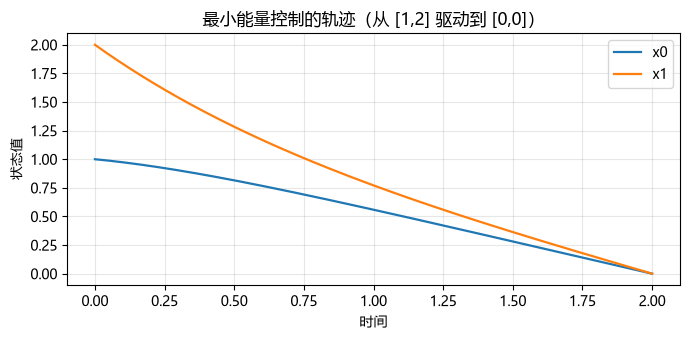

In [9]:
plt.figure(figsize=(7, 3.5))
plt.plot(trajectory.times, trajectory.states[:, 0], label="x0", linewidth=1.6)
plt.plot(trajectory.times, trajectory.states[:, 1], label="x1", linewidth=1.6)
plt.xlabel("时间")
plt.ylabel("状态值")
plt.title("最小能量控制的轨迹（从 [1,2] 驱动到 [0,0]）")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 带状态约束的最优控制

如果不想让轨迹偏离某条参考线，可以加状态惩罚：

```
J = ∫ [ ρ‖u‖² + ‖S(x - x_r)‖² ] dt
```

`rho` 越小越"舍得花能量"去贴合参考状态。

In [10]:
results = {}
for rho in (0.1, 1.0, 10.0):
    r = honet.control.optimal_control(A_norm, B2, x0, xf, T, rho=rho, S=np.eye(2), xr="zero")
    results[rho] = r
    print(f"rho={rho:5.1f}: 终点误差 {r.final_error:.2e}, 能量 {r.energy:8.4f}")

print(
    "\nrho 越大 -> 能量权重越高 -> 能量越低:",
    results[0.1].energy > results[1.0].energy > results[10.0].energy,
)

rho=  0.1: 终点误差 1.89e-12, 能量   5.4155
rho=  1.0: 终点误差 1.63e-13, 能量   1.0642
rho= 10.0: 终点误差 1.12e-13, 能量   0.7139

rho 越大 -> 能量权重越高 -> 能量越低: True


## 6. 前向仿真：给定输入，算轨迹

与上面方向相反。两者结合可以做**闭环自检**：反解出的输入喂回仿真，
必须能到达目标。

In [11]:
forward = honet.control.simulate_system(
    A_norm, B2, x0, trajectory.inputs, dt=T / (len(trajectory.times) - 1)
)
error = np.linalg.norm(forward.final_state - xf)
print(f"反解输入 -> 前向仿真 -> 终点误差: {error:.2e}")
print(f"与反解轨迹的最大偏差: {np.abs(forward.states - trajectory.states).max():.2e}")
print("闭环自检通过:", error < 1e-3)

反解输入 -> 前向仿真 -> 终点误差: 9.87e-04
与反解轨迹的最大偏差: 7.85e-04
闭环自检通过: True


## 7. 可控性度量：哪个结点是好入口

- **平均可控性**：该结点作为唯一入口时驱动系统所需的平均能量
- **模态可控性**：驱动"难控模态"的能力

In [12]:
# 用对角稳定系统，解析解为 ac_i = -1/(2 a_i)
A_diag = np.diag([-1.0, -2.0, -4.0, -8.0])
ac = honet.control.average_controllability(A_diag, "continuous")
print("平均可控性:", np.round(ac, 4))
print("解析值 -1/(2a):", np.round(-1.0 / (2.0 * np.diag(A_diag)), 4))
print("是否一致:", np.allclose(ac, -1.0 / (2.0 * np.diag(A_diag))))

ranking = honet.control.control_energy_ranking(A_diag, "continuous")
print("\n结点排名（可控性降序）:")
for node, value in ranking:
    print(f"  结点 {node}: {value:.4f}")

平均可控性: [0.5    0.25   0.125  0.0625]
解析值 -1/(2a): [0.5    0.25   0.125  0.0625]
是否一致: True

结点排名（可控性降序）:
  结点 0: 0.5000
  结点 1: 0.2500
  结点 2: 0.1250
  结点 3: 0.0625


## 8. 单纯形层：牵制哪个单纯形

如果网络是单纯复形，问题变成"牵制哪个三角形最有效"。判据是 `Δ^s`：
在 Fiedler 向量上，该单纯形内部差异越大，牵制它越能提升代数连通度 `λ₂`。

In [13]:
# 6 结点环上的三角形（2-单纯形）
SIMPLICES = [
    (0, 1, 2),
    (1, 2, 3),
    (2, 3, 4),
    (3, 4, 5),
    (4, 5, 0),
    (5, 0, 1),
]

# 1-单纯形（边）：从三角形里取出所有两两组合，去重
EDGES_1 = sorted(
    {
        (min(a, b), max(a, b))
        for tri in SIMPLICES
        for a, b in [(tri[0], tri[1]), (tri[1], tri[2]), (tri[0], tri[2])]
    }
)

print(f"1-单纯形 {len(EDGES_1)} 条:", EDGES_1)
print(f"2-单纯形 {len(SIMPLICES)} 个")

# generalized_laplacian(edges, simplices, num_nodes)：注意第一个参数是**边**，
# 第二个是**三角形**，两者不能混用。
L_simp = honet.control.generalized_laplacian(EDGES_1, SIMPLICES, num_nodes=6)
lambda2, multiplicity = honet.control.algebraic_connectivity(L_simp)
fiedler = honet.control.fiedler_vector(L_simp)

print(f"\n代数连通度 λ2 = {lambda2:.6f}（重数 {multiplicity}）")
print("Fiedler 向量:", np.round(fiedler, 4))

ranked = honet.control.rank_simplices(SIMPLICES, fiedler)
print("\n单纯形排名（Δ^s 降序）:")
for item in ranked[:4]:
    print(f"  {item.simplex}: Δ^s = {item.delta:.6f}")

1-单纯形 12 条: [(0, 1), (0, 2), (0, 4), (0, 5), (1, 2), (1, 3), (1, 5), (2, 3), (2, 4), (3, 4), (3, 5), (4, 5)]
2-单纯形 6 个

代数连通度 λ2 = 9.000000（重数 2）
Fiedler 向量: [ 0.5763  0.2579 -0.3184 -0.5763 -0.2579  0.3184]

单纯形排名（Δ^s 降序）:
  (3, 4, 5): Δ^s = 2.467864
  (0, 1, 2): Δ^s = 2.467864
  (0, 4, 5): Δ^s = 2.189050
  (1, 2, 3): Δ^s = 2.189050


### ⚠️ 这个例子恰好是反例

上面对称环的 λ₂ **重数为 2**（不是 1），于是 Fiedler 向量不唯一，
`Δ^s` 出现**并列**：(3,4,5) 与 (0,1,2) 都是 2.467864。

这不是 bug——**重数 > 1 时一阶微扰公式失效**，排序本身就没有意义。
做牵制分析前必须检查重数：

In [14]:
print(f"重数 = {multiplicity}")
if multiplicity > 1:
    print("-> λ2 重数 > 1，Fiedler 向量不唯一，Δ^s 排序不可用")
    print("-> 需要换一个 λ2 为单根的网络（下面演示）")
else:
    print("-> λ2 为单根，Δ^s 排序有效")

重数 = 2
-> λ2 重数 > 1，Fiedler 向量不唯一，Δ^s 排序不可用
-> 需要换一个 λ2 为单根的网络（下面演示）


In [15]:
# 换一个 λ2 为单根的例子：两簇 + 一条桥接三角形
SIMPLICES_ASYM = [
    (0, 1, 2),  # 簇 1
    (3, 4, 5),  # 簇 2
    (2, 3, 4),  # 桥接
]
EDGES_1_ASYM = sorted(
    {
        (min(a, b), max(a, b))
        for tri in SIMPLICES_ASYM
        for a, b in [(tri[0], tri[1]), (tri[1], tri[2]), (tri[0], tri[2])]
    }
)

L_asym = honet.control.generalized_laplacian(EDGES_1_ASYM, SIMPLICES_ASYM, num_nodes=6)
lam2_asym, mult_asym = honet.control.algebraic_connectivity(L_asym)
fiedler_asym = honet.control.fiedler_vector(L_asym)

print(f"两簇+桥: λ2 = {lam2_asym:.6f}（重数 {mult_asym}）")
print("重数为 1 -> Δ^s 排序有效:", mult_asym == 1)
print("Fiedler 向量:", np.round(fiedler_asym, 4))

ranked_asym = honet.control.rank_simplices(SIMPLICES_ASYM, fiedler_asym)
print("\n单纯形排名:")
for item in ranked_asym:
    print(f"  排名 {item.rank}: {item.simplex}  Δ^s = {item.delta:.6f}")

deltas = [item.delta for item in ranked_asym]
print("\nΔ^s 是否全部不同（无并列）:", len({round(d, 9) for d in deltas}) == len(deltas))
print("最该牵制的单纯形:", ranked_asym[0].simplex)

两簇+桥: λ2 = 1.527864（重数 1）
重数为 1 -> Δ^s 排序有效: True
Fiedler 向量: [ 0.5117  0.5117  0.1208 -0.3162 -0.3162 -0.5117]

单纯形排名:
  排名 1: (2, 3, 4)  Δ^s = 0.763932
  排名 2: (0, 1, 2)  Δ^s = 0.611146
  排名 3: (3, 4, 5)  Δ^s = 0.152786

Δ^s 是否全部不同（无并列）: True
最该牵制的单纯形: (2, 3, 4)


In [16]:
# 牵制矩阵：在被牵制单纯形的 1-单纯形上加权重
E = honet.control.pinning_matrix(SIMPLICES, num_nodes=6, weight=0.5)
print("牵制矩阵形状:", E.shape)
print("非零元个数:", np.count_nonzero(E))
print("\n牵制矩阵:")
print(np.round(E, 2))

牵制矩阵形状: (6, 6)
非零元个数: 30

牵制矩阵:
[[ 3.  -1.  -0.5  0.  -0.5 -1. ]
 [-1.   3.  -1.  -0.5  0.  -0.5]
 [-0.5 -1.   3.  -1.  -0.5  0. ]
 [ 0.  -0.5 -1.   3.  -1.  -0.5]
 [-0.5  0.  -0.5 -1.   3.  -1. ]
 [-1.  -0.5  0.  -0.5 -1.   3. ]]


## 9. 批量控制能量：所有状态对之间的转移

脑网络控制文献的常见分析：把结点分成若干系统，算系统 A → B 的能量。

In [17]:
A6 = honet.control.matrix_normalization(
    np.array(
        [
            [0.0, 1.0, 0, 0, 0, 1.0],
            [1.0, 0.0, 1.0, 0, 0, 0],
            [0, 1.0, 0.0, 1.0, 0, 0],
            [0, 0, 1.0, 0.0, 1.0, 0],
            [0, 0, 0, 1.0, 0.0, 1.0],
            [1.0, 0, 0, 0, 1.0, 0.0],
        ]
    ),
    "continuous",
)

batch = honet.control.control_energy_matrix(
    A6, np.eye(6), labels=["A", "A", "B", "B", "C", "C"], T=1.0
)
print("能量矩阵形状:", batch.energies.shape)
print(np.round(batch.energies, 4))
print("\n最难转移:", batch.hardest())
print("最易转移:", batch.easiest())

能量矩阵形状: (3, 3)
[[0.5101 2.2822 2.2822]
 [2.2822 0.5101 2.2822]
 [2.2822 2.2822 0.5101]]

最难转移: ('A', 'C', np.float64(2.28215356238986))
最易转移: ('B', 'B', np.float64(0.510054336936745))


## 小结

| 你想做什么 | 用哪个 |
| --- | --- |
| 构造超图 Laplacian | `hypergraph_laplacian(edges, num_nodes, order=m)` |
| 组装动力学系统 | `HypergraphControlSystem(A, L, Lambda, B, ...)` |
| 判断能否控制 | `kalman_rank` / `is_controllable` / `pbh_rank` |
| 最省力的输入 | `minimum_energy_control(A, B, x0, xf, T)` |
| 带状态约束 | `optimal_control(..., rho, S, xr)` |
| 输入 → 轨迹 | `simulate_system(A, B, x0, U)` |
| 选控制入口 | `average_controllability` / `control_energy_ranking` |
| 选牵制单纯形 | `rank_simplices` / `pinning_matrix` |
| 系统间转移能量 | `control_energy_matrix(A, B, labels, T)` |

**三条关键提醒**：

1. **Laplacian 的阶数会改变结果**。`order=2` 与 `order=3` 给出不同矩阵，
   写错会让高阶项完全失效（本 notebook 已对比验证）。
2. **稳态量需要稳定系统**。`average_controllability` / `infinite_gramian`
   对不稳定系统会抛 `ValueError`，先用 `matrix_normalization` 归一化。
3. **`Δ^s` 排序要求 λ₂ 是单根**。重数 > 1 时 Fiedler 向量不唯一，
   一阶近似失效（本 notebook 已检查重数）。